# DenseNet-121 Model

## Import Libraries and Set Configurations

In [1]:
# Import the relevant libraries
from utils.seed_utils import *
from utils.data_utils import *
from utils.training_evaluation_utils import *
from utils.external_validation_utils import *
from utils.cache_utils import *
from utils.results_utils import *
from utils.experiment_runner import (run_single_experiment as shared_run_single_experiment)

import os
import json
import copy
import numpy as np
import pandas as pd
import torch.optim as optim
import torch
import torch.nn as nn
from functools import partial

from sklearn.utils.class_weight import compute_class_weight
from torchvision import models
from torchvision.models import DenseNet121_Weights

import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader

In [2]:
# List the configurations
DATA_DIR = "../data/EBHI-SEG"

BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGE_SIZE = 224
NUM_EPOCHS_STAGE1 = 15
NUM_EPOCHS_STAGE2 = 25

LR_STAGE1 = 1e-3
LR_STAGE2 = 3e-5

WEIGHT_DECAY = 1e-4
PATIENCE = 5
LABEL_SMOOTHING = 0.05

## Multi-Run Configuration

In [3]:
# Multi-run configuration
SPLIT_SEED = 42
RUN_SEEDS = [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888]

N_RUNS = len(RUN_SEEDS)
CACHE_DIR = "outputs/densenet121/run_cache"
RESULTS_DIR = "outputs/densenet121"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

SAVE_MODEL_PER_RUN = True
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Using device:", DEVICE)
print(f"Planned runs: {N_RUNS} (seeds {RUN_SEEDS})")

Using device: mps
Planned runs: 10 (seeds [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888])


## Caching Functions

In [4]:
# Configure shared caching functions for this architecture
run_cache_path = partial(run_cache_path, cache_dir=CACHE_DIR)
run_model_path = partial(run_model_path, cache_dir=CACHE_DIR)
load_cached_run = partial(load_cached_run, cache_dir=CACHE_DIR)
save_run_cache = partial(save_run_cache, cache_dir=CACHE_DIR)

## Building the DenseNet-121 Model

In [5]:
# Function to build the DenseNet-121 model with a custom classifier head
def build_densenet121(num_classes):
    weights = DenseNet121_Weights.DEFAULT
    model = models.densenet121(weights=weights)
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(512, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, num_classes)
    )
    return model


# Function to freeze backbone
def freeze_backbone(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.classifier.parameters():
        param.requires_grad = True


# Function to unfreeze for fine-tuning
def unfreeze_for_finetuning(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.classifier.parameters():
        param.requires_grad = True
    # Fine-tune deeper DenseNet blocks
    for param in model.features.denseblock4.parameters():
        param.requires_grad = True
    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

## External Validation Configuration

In [6]:
EXTERNAL_DIR = "../data/lung_colon_image_set/Test Set"
EXTERNAL_IMAGE_SIZE = 224
EXTERNAL_BATCH_SIZE = 16
EXTERNAL_NUM_WORKERS = 0

external_class_names = [
    "Adenocarcinoma",
    "High-grade IN",
    "Low-grade IN",
    "Normal",
    "Polyp",
    "Serrated adenoma"
]
external_class_to_index = {cls: i for i, cls in enumerate(external_class_names)}

external_label_map = {
    "colon_aca": "Adenocarcinoma",
    "colon_n": "Normal"
}

external_labels = [external_class_to_index[c] for c in external_label_map.values()]
external_target_names = list(external_label_map.values())

## Single-Run Experiment

In [7]:
def run_single_experiment(run_idx, seed):
    return shared_run_single_experiment(
        run_idx=run_idx,
        seed=seed,

        # Architecture-specific configuration
        model_name="DenseNet-121",
        build_model=build_densenet121,
        freeze_backbone=freeze_backbone,
        unfreeze_for_finetuning=unfreeze_for_finetuning,

        # Dataset and preprocessing
        data_dir=DATA_DIR,
        split_seed=SPLIT_SEED,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        device=DEVICE,

        # Training configuration
        label_smoothing=LABEL_SMOOTHING,
        lr_stage1=LR_STAGE1,
        lr_stage2=LR_STAGE2,
        weight_decay=WEIGHT_DECAY,
        num_epochs_stage1=NUM_EPOCHS_STAGE1,
        num_epochs_stage2=NUM_EPOCHS_STAGE2,
        patience=PATIENCE,

        # External validation
        external_dir=EXTERNAL_DIR,
        external_label_map=external_label_map,
        external_class_to_index=external_class_to_index,
        external_image_size=EXTERNAL_IMAGE_SIZE,
        external_batch_size=EXTERNAL_BATCH_SIZE,
        external_num_workers=EXTERNAL_NUM_WORKERS,
        external_labels=external_labels,
        external_target_names=external_target_names,
        external_class_names=external_class_names,

        # Checkpoint saving
        save_model_per_run=SAVE_MODEL_PER_RUN,
        model_path_fn=run_model_path,
    )


## Run a Single Experiment (with caching)

In [8]:
# Configure the shared run-or-load function
run_or_load = partial(
    run_or_load,
    cache_dir=CACHE_DIR,
    run_single_experiment=run_single_experiment
)

## Execute All Runs

Runs (or loads from cache) each of the `N_RUNS` repetitions in sequence

In [9]:
all_run_results = []

for i, seed in enumerate(RUN_SEEDS):
    result = run_or_load(i, seed)
    all_run_results.append(result)

print(f"\nCollected {len(all_run_results)} / {N_RUNS} runs.")

[cache] Run 0 (seed=42) already cached — skipping training.
[cache] Run 1 (seed=123) already cached — skipping training.
[cache] Run 2 (seed=2024) already cached — skipping training.
[cache] Run 3 (seed=3407) already cached — skipping training.
[cache] Run 4 (seed=9999) already cached — skipping training.
[cache] Run 5 (seed=7) already cached — skipping training.
[cache] Run 6 (seed=77) already cached — skipping training.
[cache] Run 7 (seed=314) already cached — skipping training.
[cache] Run 8 (seed=2025) already cached — skipping training.
[cache] Run 9 (seed=8888) already cached — skipping training.

Collected 10 / 10 runs.


## Aggregate Results: Mean ± SD

In [10]:
sections = {
    "Internal Test (Normal, no TTA)": "internal_normal",
    "Internal Test (TTA)": "internal_tta",
    "External Validation (Normal, no TTA)": "external_normal",
    "External Validation (TTA)": "external_tta",
}

summary_tables = {}
for title, key in sections.items():
    df = aggregate_section(all_run_results, key)
    summary_tables[key] = df
    print("\n" + "=" * 70)
    print(title, f"(n={len(all_run_results)} runs)")
    print("=" * 70)
    if df.empty:
        print("No numeric metrics found for this section.")
    else:
        print(df[["metric", "mean_pm_sd"]].to_string(index=False))


Internal Test (Normal, no TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8910 ± 0.0162
        f1_macro 0.8190 ± 0.0274
            loss 0.8726 ± 0.0455
   macro_roc_auc 0.9740 ± 0.0072
 precision_macro 0.8054 ± 0.0354
    recall_macro 0.8447 ± 0.0279
weighted_roc_auc 0.9839 ± 0.0038

Internal Test (TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.9057 ± 0.0101
        f1_macro 0.8551 ± 0.0134
            loss 0.9782 ± 0.0267
   macro_roc_auc 0.9832 ± 0.0035
 precision_macro 0.8306 ± 0.0185
    recall_macro 0.8940 ± 0.0132
weighted_roc_auc 0.9887 ± 0.0021

External Validation (Normal, no TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.5094 ± 0.0591
 macro_f1 0.5773 ± 0.0713
precision 0.8453 ± 0.0435
   recall 0.5094 ± 0.0591

External Validation (TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.5411 ± 0.0678
 macro_f1 0.6081 ± 0.0780
precision 0.8676 ± 0.0392
   recall 0.5411 ± 0.0678


## Save the Aggregated Summary and Per-Run Table
- `densenet121_multirun_summary.json`: mean/SD for every metric, per section
- `densenet121_multirun_per_run.csv`: the raw per-run scalar metrics (one row per run)
- Each individual run's full result is also available in `outputs/densenet121/run_cache/`

In [11]:
# Save mean +/- SD summary 
summary_json = {
    title: df.to_dict(orient="records")
    for title, df in zip(sections.keys(), summary_tables.values())
}
summary_json["n_runs"] = len(all_run_results)
summary_json["seeds"] = [r["seed"] for r in all_run_results]

summary_path = os.path.join(RESULTS_DIR, "densenet121_multirun_summary.json")
with open(summary_path, "w") as f:
    json.dump(summary_json, f, indent=2)
print("Saved aggregated summary to:", summary_path)

# Save a flat per-run CSV for transparency/re-analysis 
per_run_rows = []
for r in all_run_results:
    row = {"run_idx": r["run_idx"], "seed": r["seed"]}
    for section_key in ["internal_normal", "internal_tta", "external_normal", "external_tta"]:
        if section_key in r:
            for k, v in flatten_numeric(r[section_key]).items():
                row[f"{section_key}.{k}"] = v
    per_run_rows.append(row)

per_run_df = pd.DataFrame(per_run_rows)
per_run_csv_path = os.path.join(RESULTS_DIR, "densenet121_multirun_per_run.csv")
per_run_df.to_csv(per_run_csv_path, index=False)
print("Saved per-run metrics to:", per_run_csv_path)
per_run_df

Saved aggregated summary to: outputs/densenet121/densenet121_multirun_summary.json
Saved per-run metrics to: outputs/densenet121/densenet121_multirun_per_run.csv


,run_idx,seed,internal_normal.loss,internal_normal.accuracy,internal_normal.precision_macro,internal_normal.recall_macro,internal_normal.f1_macro,internal_normal.macro_roc_auc,internal_normal.weighted_roc_auc,internal_tta.loss,...,internal_tta.macro_roc_auc,internal_tta.weighted_roc_auc,external_normal.accuracy,external_normal.precision,external_normal.recall,external_normal.macro_f1,external_tta.accuracy,external_tta.precision,external_tta.recall,external_tta.macro_f1
0,0,42,0.876523,0.898507,0.810360,0.818190,0.811392,0.975777,0.985370,0.976724,...,0.983459,0.989362,0.549,0.873301,0.549,0.623194,0.588,0.899615,0.588,0.663536
1,1,123,0.831831,0.901493,0.828936,0.875416,0.843830,0.978541,0.987439,0.946920,...,0.988046,0.991819,0.502,0.840797,0.502,0.551608,0.530,0.859844,0.530,0.571809
2,2,2024,0.892461,0.871642,0.769342,0.825896,0.790617,0.969874,0.981141,0.994544,...,0.976248,0.986404,0.428,0.780992,0.428,0.494592,0.443,0.804467,0.443,0.506297
3,3,3407,0.852911,0.913433,0.867829,0.848646,0.856906,0.975324,0.987473,0.943308,...,0.981066,0.990139,0.526,0.893418,0.526,0.620372,0.552,0.903187,0.552,0.641015
4,4,9999,0.964847,0.874627,0.777430,0.816090,0.792267,0.955714,0.975668,1.012767,...,0.982026,0.985881,0.462,0.817911,0.462,0.500635,0.487,0.832119,0.487,0.529702
5,5,7,0.879723,0.901493,0.836447,0.860881,0.839328,0.976775,0.982935,0.993962,...,0.982717,0.987340,0.515,0.917344,0.515,0.582041,0.543,0.924152,0.543,0.607290
6,6,77,0.829141,0.901493,0.804245,0.865098,0.828622,0.977018,0.986205,0.950349,...,0.983325,0.989996,0.477,0.855338,0.477,0.531498,0.518,0.880072,0.518,0.588218
7,7,314,0.831013,0.889552,0.790227,0.885618,0.825541,0.981182,0.986235,0.985444,...,0.986450,0.989371,0.615,0.855912,0.615,0.689758,0.632,0.875616,0.632,0.702257
8,8,2025,0.840682,0.895522,0.821428,0.848977,0.831483,0.977319,0.986405,0.962056,...,0.987411,0.990890,0.445,0.787171,0.445,0.508191,0.467,0.816339,0.467,0.530758
9,9,8888,0.926814,0.862687,0.748095,0.802518,0.769899,0.971981,0.980366,1.015778,...,0.981410,0.986169,0.575,0.831002,0.575,0.671210,0.651,0.880810,0.651,0.740385


## Confusion Matrix for a Single Reference Run

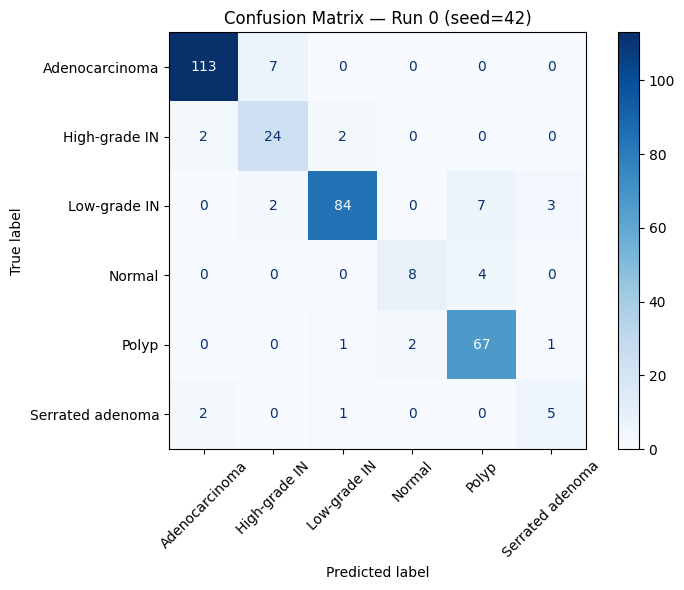

In [12]:
reference_run = all_run_results[0]

cm_ref = np.array(reference_run["internal_normal_extra"]["confusion_matrix"])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_ref,
    display_labels=reference_run["class_names"]
)
fig, ax = plt.subplots(figsize=(8, 6))
display.plot(cmap="Blues", ax=ax, values_format="d")
plt.title(f"Confusion Matrix — Run {reference_run['run_idx']} (seed={reference_run['seed']})")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()